In [2]:
#Librerias
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from scipy import stats
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
import joblib

In [3]:
# 1. EDA
df = pd.read_csv('./archive/AmesHousing.csv')
print(df.size)

240260


?
Caracteristicas altamente correlacionadas:
   Caracteristica 1 Caracteristica 2  Correlacion
0            Order          Yr Sold    -0.975993
1       Year Built    Garage Yr Blt     0.834849
2    Total Bsmt SF       1st Flr SF     0.800720
3       1st Flr SF    Total Bsmt SF     0.800720
4      Gr Liv Area    TotRms AbvGrd     0.807772
5    TotRms AbvGrd      Gr Liv Area     0.807772
6    Garage Yr Blt       Year Built     0.834849
7      Garage Cars      Garage Area     0.889676
8      Garage Area      Garage Cars     0.889676
9          Yr Sold            Order    -0.975993


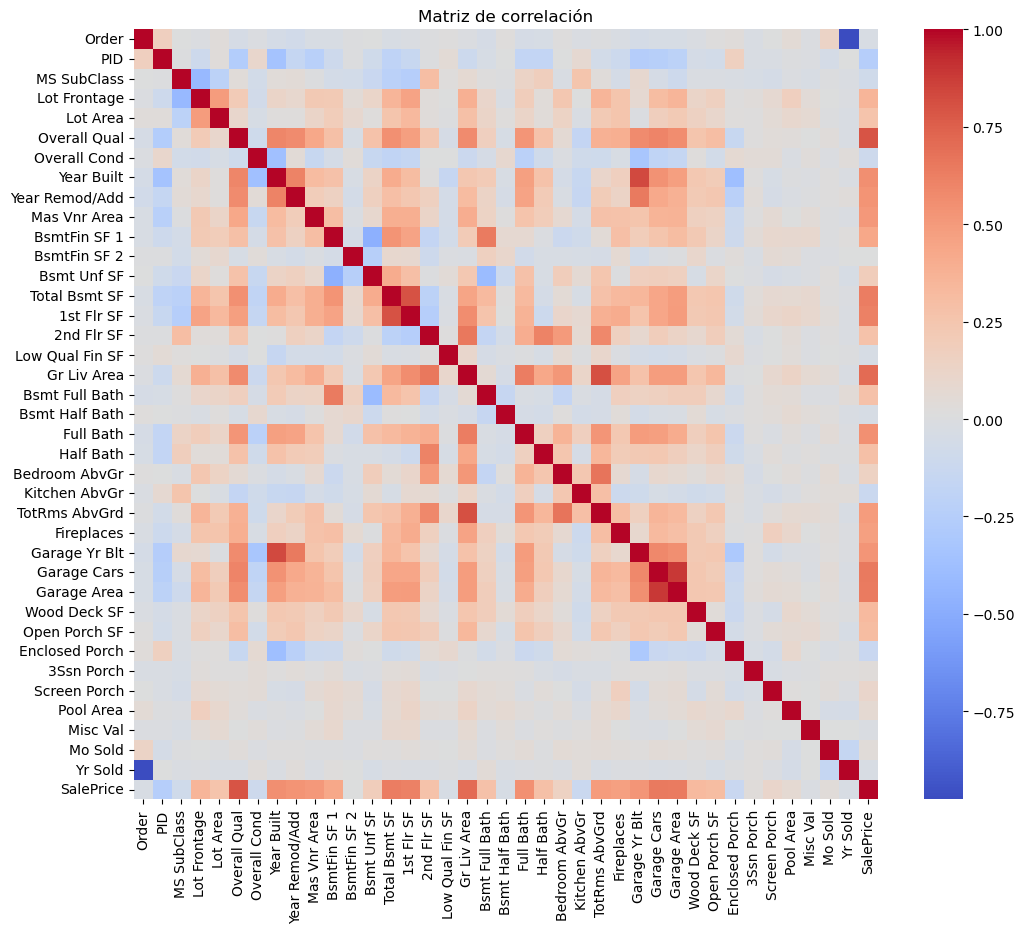

In [4]:
#Matriz de correlacion
df1 = df.select_dtypes(include=[np.number])
df1.columns = df1.columns.str.strip()
matriz_correlacion = df1.corr()
caracteristicas_alta_correlacion = [(col1, col2, matriz_correlacion.loc[col1,col2])
                                   for col1 in matriz_correlacion.columns
                                   for col2 in matriz_correlacion.columns
                                   if col1 != col2 and abs(matriz_correlacion.loc[col1,col2])>0.8]
multicolinealidad_df = pd.DataFrame(caracteristicas_alta_correlacion, columns = ["Caracteristica 1","Caracteristica 2","Correlacion"])
print("?\nCaracteristicas altamente correlacionadas:\n", multicolinealidad_df)

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_correlacion, cmap='coolwarm', annot=False)
plt.title("Matriz de correlación")
plt.show()

Correlacion de cada variable con SalePrice :

SalePrice          1.000000
Overall Qual       0.799262
Gr Liv Area        0.706780
Garage Cars        0.647877
Garage Area        0.640401
Total Bsmt SF      0.632280
1st Flr SF         0.621676
Year Built         0.558426
Full Bath          0.545604
Year Remod/Add     0.532974
Garage Yr Blt      0.526965
Mas Vnr Area       0.508285
TotRms AbvGrd      0.495474
Fireplaces         0.474558
BsmtFin SF 1       0.432914
Lot Frontage       0.357318
Wood Deck SF       0.327143
Open Porch SF      0.312951
Half Bath          0.285056
Bsmt Full Bath     0.276050
2nd Flr SF         0.269373
Lot Area           0.266549
Bsmt Unf SF        0.182855
Bedroom AbvGr      0.143913
Screen Porch       0.112151
Pool Area          0.068403
Mo Sold            0.035259
3Ssn Porch         0.032225
BsmtFin SF 2       0.005891
Misc Val          -0.015691
Yr Sold           -0.030569
Order             -0.031408
Bsmt Half Bath    -0.035835
Low Qual Fin SF   -0.037660
MS

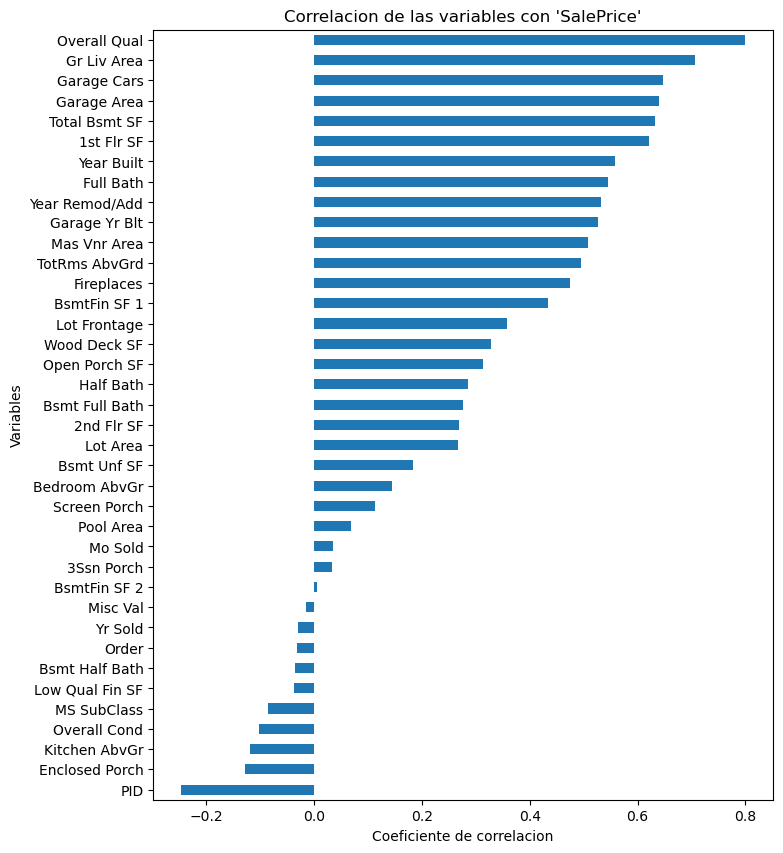

In [5]:
#Relacion a variable dependiente
variable_dependiente = 'SalePrice'
df_num = df.select_dtypes(include=[np.number])
correlaciones = df_num.corr()[variable_dependiente].sort_values(ascending=False)

print("Correlacion de cada variable con", variable_dependiente, ":\n")
print(correlaciones)
print("\n Variables con mayor correlacion:")
print(correlaciones.head(10))
print("\n Variables con menor correlacion:")
print(correlaciones.tail(10))

correlaciones.drop(variable_dependiente).sort_values(ascending=True).plot(kind='barh', figsize=(8,10))
plt.title(f"Correlacion de las variables con '{variable_dependiente}'")
plt.xlabel("Coeficiente de correlacion")
plt.ylabel("Variables")
plt.show()

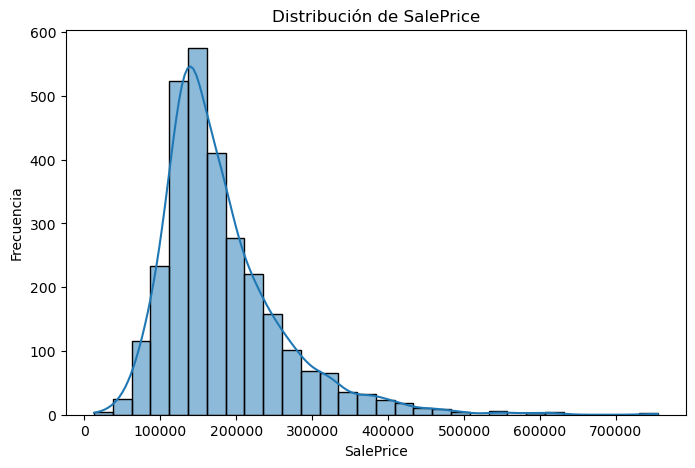

In [6]:
#Histograma
plt.figure(figsize=(8,5))
sns.histplot(df[variable_dependiente], bins=30, kde=True)
plt.title(f'Distribución de {variable_dependiente}')
plt.xlabel(variable_dependiente)
plt.ylabel('Frecuencia')
plt.show()

Variables mas correlacionadas con la dependiente:
 Overall Qual     0.799262
Gr Liv Area      0.706780
Garage Cars      0.647877
Garage Area      0.640401
Total Bsmt SF    0.632280
1st Flr SF       0.621676
Name: SalePrice, dtype: float64


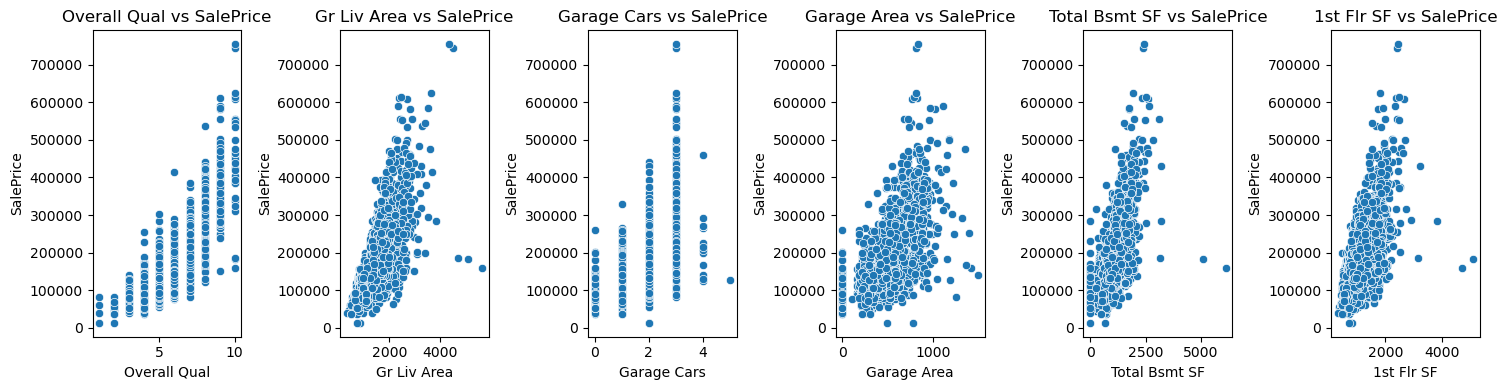


 Datos que hay: 240260


In [7]:
#Diagrama de dispersion
print("Variables mas correlacionadas con la dependiente:\n", correlaciones[1:7])
variables_top = correlaciones[1:7].index.tolist()

plt.figure(figsize=(15,4))
for i, col in enumerate(variables_top, 1):
    plt.subplot(1, 6, i)
    sns.scatterplot(x=df[col], y=df[variable_dependiente])
    plt.title(f'{col} vs {variable_dependiente}')
plt.tight_layout()
plt.show()

print("\n Datos que hay: " + str(df.size))

In [8]:
# 2. Preprocesamiento de los datos

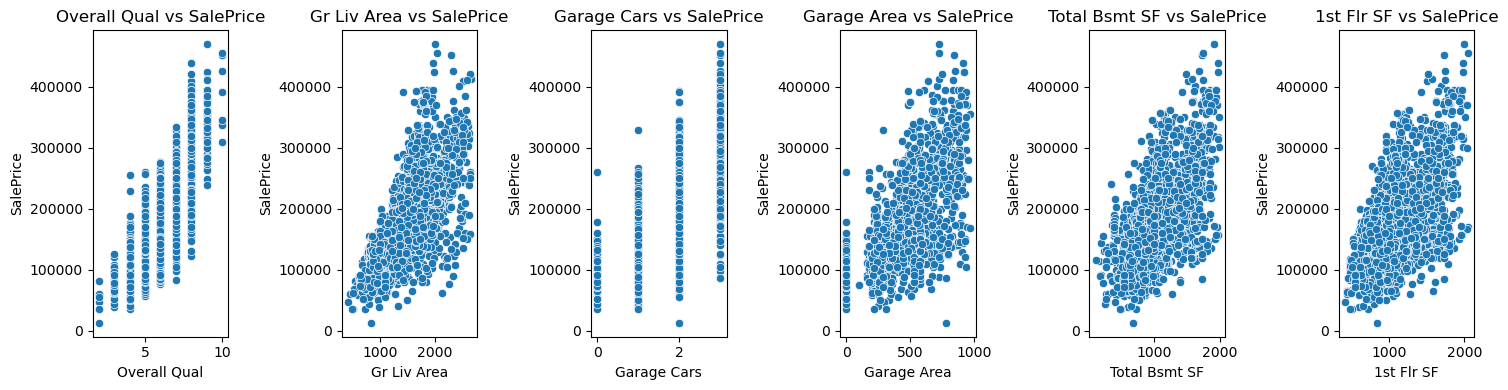


 Datos que hay: 220252


In [9]:
# Manejo de valor atipicos
for col in variables_top:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    df = df[(df[col] >= lim_inf) & (df[col] <= lim_sup)]

plt.figure(figsize=(15,4))
for i, col in enumerate(variables_top, 1):
    plt.subplot(1, 6, i)
    sns.scatterplot(x=df[col], y=df[variable_dependiente])
    plt.title(f'{col} vs {variable_dependiente}')
plt.tight_layout()
plt.show()

print("\n Datos que hay: " + str(df.size))

In [10]:
# Manejo de valores nulos
df = df.drop(columns=['PID'])

porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
print(porcentaje_nulos)

for col in df.columns:
    porcentaje_nulos2 = (df[col].isnull().sum() / len(df)) * 100

    if porcentaje_nulos2 == 0:
        continue
    elif porcentaje_nulos2 < 5:
        df = df.dropna(subset=[col])

    else:
        if df[col].dtype in ['float64', 'int64']:
            df[col] = df[col].fillna(df[col].mean())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])


Order              0.000000
MS SubClass        0.000000
MS Zoning          0.000000
Lot Frontage      16.641847
Lot Area           0.000000
                    ...    
Mo Sold            0.000000
Yr Sold            0.000000
Sale Type          0.000000
Sale Condition     0.000000
SalePrice          0.000000
Length: 81, dtype: float64


In [11]:
# Ya no hay nulos :D
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
print(porcentaje_nulos)
print("\n Datos que hay: " + str(df.size))

Order             0.0
MS SubClass       0.0
MS Zoning         0.0
Lot Frontage      0.0
Lot Area          0.0
                 ... 
Mo Sold           0.0
Yr Sold           0.0
Sale Type         0.0
Sale Condition    0.0
SalePrice         0.0
Length: 81, dtype: float64

 Datos que hay: 215541


In [12]:
#Codificacion de variables
categoricas = df.select_dtypes(include=['object', 'category']).columns
cat_peq = [c for c in categoricas if df[c].nunique() <= 10]
cat_grand = [c for c in categoricas if df[c].nunique() > 10]

df = pd.get_dummies(df, columns=cat_peq, drop_first=True)

for col in cat_grand:
    target_means = df.groupby(col)['SalePrice'].mean()
    df[col + '_encoded'] = df[col].map(target_means)
    df.drop(columns=col, inplace=True)

print("\n Datos que hay: " + str(df.size))


 Datos que hay: 529539


In [13]:
# 3. Division de los Datos
y = df['SalePrice']
X = df.drop(columns=['SalePrice'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=101)

In [14]:
# 4. Entrenamiento del Modelo

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)       

elastic = ElasticNet(max_iter=5000)
param_grid = {
    'alpha': [0.1, 1, 5, 10, 50, 100],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1]
}

grid = GridSearchCV(
    estimator=elastic,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Mejores hiperparametros:", grid.best_params_)

joblib.dump(grid.best_estimator_, 'elasticnet_model.joblib')
joblib.dump(scaler, 'scaler.joblib')                         
joblib.dump(X_test_scaled, 'X_test_scaled.joblib')      
joblib.dump(y_test, 'y_test.joblib')       

Mejores hiperparametros: {'alpha': 100, 'l1_ratio': 1}


['y_test.joblib']